# Modelo C4 de La Colmena

Este cuaderno presenta los niveles **C1 Contexto**, **C2 Contenedores** y **C3 Componentes** de la arquitectura actual. Los diagramas se dibujan como SVG desde celdas Python y no requieren paquetes gráficos ni recursos externos.

**Alcance:** monolito Python con interfaz HTML/JavaScript, API HTTP, SQLite y publicación asíncrona de CloudEvents a Apache Kafka. El pago es simulado dentro del proceso.

> Los diagramas reflejan el estado *as-is*. En C3 se muestran explícitamente SQL directo desde `app.py` y el uso de una conexión SQLite en la Saga; por ello no se afirma que los Bounded Contexts ya tengan aislamiento técnico estricto.


## C1 — Contexto del sistema

Administradora, vendedor y cliente interactúan con La Colmena mediante la interfaz web. El sistema publica CloudEvents en Kafka. La pasarela de pago es actualmente un mock interno, por lo que no se representa como sistema externo.


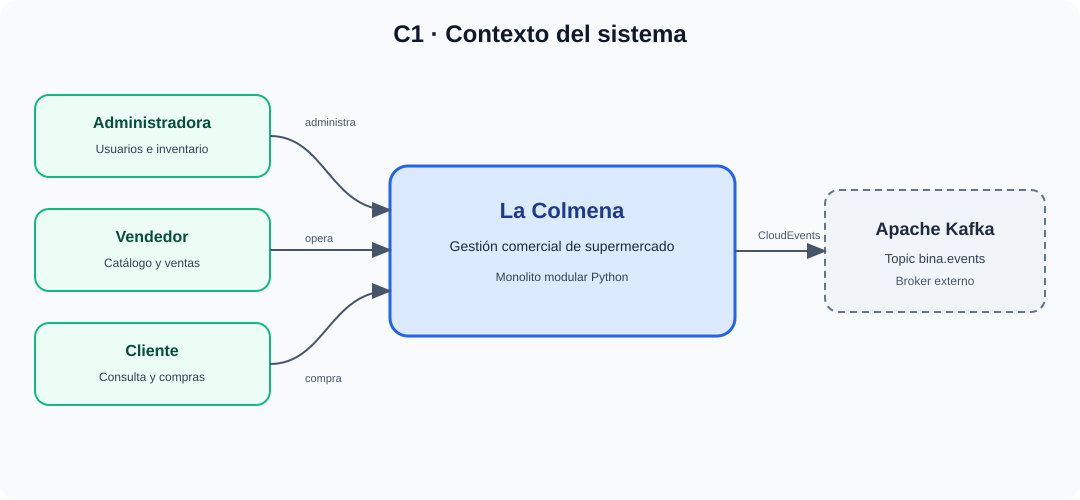

In [1]:
from IPython.display import SVG, display

display(SVG("""
<svg xmlns='http://www.w3.org/2000/svg' viewBox='0 0 1080 500' role='img' aria-label='Diagrama C1 de contexto de La Colmena'>
  <defs><marker id='c1-arrow' markerWidth='10' markerHeight='8' refX='9' refY='4' orient='auto'><path d='M0,0 L10,4 L0,8 Z' fill='#475569'/></marker></defs>
  <rect width='1080' height='500' rx='18' fill='#f8fafc'/>
  <text x='540' y='42' text-anchor='middle' font-family='Arial' font-size='24' font-weight='700' fill='#0f172a'>C1 · Contexto del sistema</text>
  <g font-family='Arial'>
    <rect x='35' y='95' width='235' height='82' rx='14' fill='#ecfdf5' stroke='#10b981' stroke-width='2'/>
    <text x='152' y='128' text-anchor='middle' font-size='16' font-weight='700' fill='#064e3b'>Administradora</text><text x='152' y='153' text-anchor='middle' font-size='12' fill='#334155'>Usuarios e inventario</text>
    <rect x='35' y='209' width='235' height='82' rx='14' fill='#ecfdf5' stroke='#10b981' stroke-width='2'/>
    <text x='152' y='242' text-anchor='middle' font-size='16' font-weight='700' fill='#064e3b'>Vendedor</text><text x='152' y='267' text-anchor='middle' font-size='12' fill='#334155'>Catálogo y ventas</text>
    <rect x='35' y='323' width='235' height='82' rx='14' fill='#ecfdf5' stroke='#10b981' stroke-width='2'/>
    <text x='152' y='356' text-anchor='middle' font-size='16' font-weight='700' fill='#064e3b'>Cliente</text><text x='152' y='381' text-anchor='middle' font-size='12' fill='#334155'>Consulta y compras</text>
    <rect x='390' y='166' width='345' height='170' rx='18' fill='#dbeafe' stroke='#2563eb' stroke-width='3'/>
    <text x='562' y='218' text-anchor='middle' font-size='22' font-weight='700' fill='#1e3a8a'>La Colmena</text><text x='562' y='251' text-anchor='middle' font-size='14' fill='#1e293b'>Gestión comercial de supermercado</text><text x='562' y='281' text-anchor='middle' font-size='12' fill='#334155'>Monolito modular Python</text>
    <rect x='825' y='190' width='220' height='122' rx='14' fill='#f1f5f9' stroke='#64748b' stroke-width='2' stroke-dasharray='7 5'/>
    <text x='935' y='235' text-anchor='middle' font-size='18' font-weight='700' fill='#1e293b'>Apache Kafka</text><text x='935' y='263' text-anchor='middle' font-size='13' fill='#334155'>Topic bina.events</text><text x='935' y='285' text-anchor='middle' font-size='12' fill='#475569'>Broker externo</text>
  </g>
  <g fill='none' stroke='#475569' stroke-width='2' marker-end='url(#c1-arrow)'>
    <path d='M270 136 C325 136 330 210 390 210'/><path d='M270 250 L390 250'/><path d='M270 364 C325 364 330 291 390 291'/><path d='M735 251 L825 251'/>
  </g>
  <g font-family='Arial' font-size='11' fill='#475569'><text x='305' y='126'>administra</text><text x='305' y='242'>opera</text><text x='305' y='382'>compra</text><text x='758' y='239'>CloudEvents</text></g>
</svg>
"""))


## C2 — Contenedores

La interfaz se ejecuta en el navegador; `src/app.py` sirve la API y coordina rutas/Saga en el proceso Python. SQLite es el almacenamiento local y el worker de outbox publica al broker Kafka.


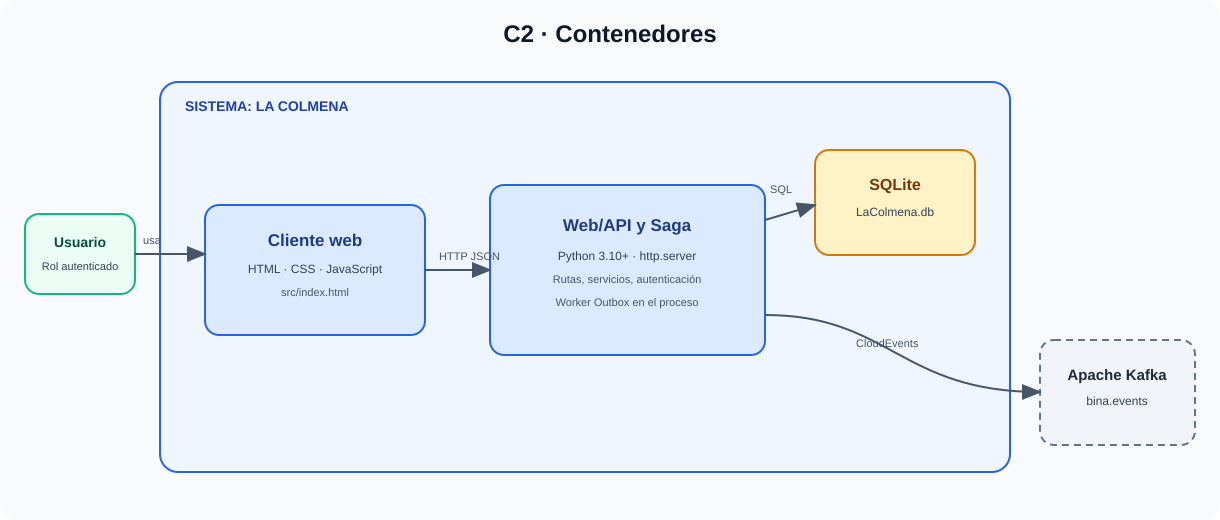

In [2]:
from IPython.display import SVG, display

display(SVG("""
<svg xmlns='http://www.w3.org/2000/svg' viewBox='0 0 1220 520' role='img' aria-label='Diagrama C2 de contenedores de La Colmena'>
  <defs><marker id='c2-arrow' markerWidth='10' markerHeight='8' refX='9' refY='4' orient='auto'><path d='M0,0 L10,4 L0,8 Z' fill='#475569'/></marker></defs>
  <rect width='1220' height='520' rx='18' fill='#f8fafc'/>
  <text x='610' y='42' text-anchor='middle' font-family='Arial' font-size='24' font-weight='700' fill='#0f172a'>C2 · Contenedores</text>
  <rect x='160' y='82' width='850' height='390' rx='18' fill='#eff6ff' stroke='#2563eb' stroke-width='2'/>
  <text x='185' y='111' font-family='Arial' font-size='14' font-weight='700' fill='#1e40af'>SISTEMA: LA COLMENA</text>
  <g font-family='Arial'>
    <rect x='25' y='214' width='110' height='80' rx='14' fill='#ecfdf5' stroke='#10b981' stroke-width='2'/><text x='80' y='247' text-anchor='middle' font-size='14' font-weight='700' fill='#064e3b'>Usuario</text><text x='80' y='270' text-anchor='middle' font-size='11' fill='#334155'>Rol autenticado</text>
    <rect x='205' y='205' width='220' height='130' rx='14' fill='#dbeafe' stroke='#2563eb' stroke-width='2'/><text x='315' y='246' text-anchor='middle' font-size='17' font-weight='700' fill='#1e3a8a'>Cliente web</text><text x='315' y='273' text-anchor='middle' font-size='12' fill='#334155'>HTML · CSS · JavaScript</text><text x='315' y='296' text-anchor='middle' font-size='11' fill='#475569'>src/index.html</text>
    <rect x='490' y='185' width='275' height='170' rx='14' fill='#dbeafe' stroke='#2563eb' stroke-width='2'/><text x='627' y='231' text-anchor='middle' font-size='17' font-weight='700' fill='#1e3a8a'>Web/API y Saga</text><text x='627' y='260' text-anchor='middle' font-size='12' fill='#334155'>Python 3.10+ · http.server</text><text x='627' y='283' text-anchor='middle' font-size='11' fill='#475569'>Rutas, servicios, autenticación</text><text x='627' y='306' text-anchor='middle' font-size='11' fill='#475569'>Worker Outbox en el proceso</text>
    <rect x='815' y='150' width='160' height='105' rx='14' fill='#fef3c7' stroke='#d97706' stroke-width='2'/><text x='895' y='190' text-anchor='middle' font-size='16' font-weight='700' fill='#78350f'>SQLite</text><text x='895' y='216' text-anchor='middle' font-size='12' fill='#334155'>LaColmena.db</text>
    <rect x='1040' y='340' width='155' height='105' rx='14' fill='#f1f5f9' stroke='#64748b' stroke-width='2' stroke-dasharray='7 5'/><text x='1117' y='380' text-anchor='middle' font-size='15' font-weight='700' fill='#1e293b'>Apache Kafka</text><text x='1117' y='405' text-anchor='middle' font-size='12' fill='#334155'>bina.events</text>
  </g>
  <g fill='none' stroke='#475569' stroke-width='2' marker-end='url(#c2-arrow)'><path d='M135 254 L205 254'/><path d='M425 270 L490 270'/><path d='M765 220 L815 205'/><path d='M765 315 C890 315 900 392 1040 392'/></g>
  <g font-family='Arial' font-size='11' fill='#475569'><text x='143' y='244'>usa</text><text x='439' y='260'>HTTP JSON</text><text x='770' y='193'>SQL</text><text x='856' y='347'>CloudEvents</text></g>
</svg>
"""))


## C3 — Componentes del contenedor Python

Los módulos reflejan las responsabilidades reales: adaptador HTTP (`app.py`), seguridad (`auth.py`), Saga (`services.py`), modelo/validadores, puertos, repositorios, eventos, outbox y logging. Las flechas rotuladas **SQL directo** y **transacción SQLite** son dependencias actuales que deben desaparecer para lograr límites estrictos entre contextos.


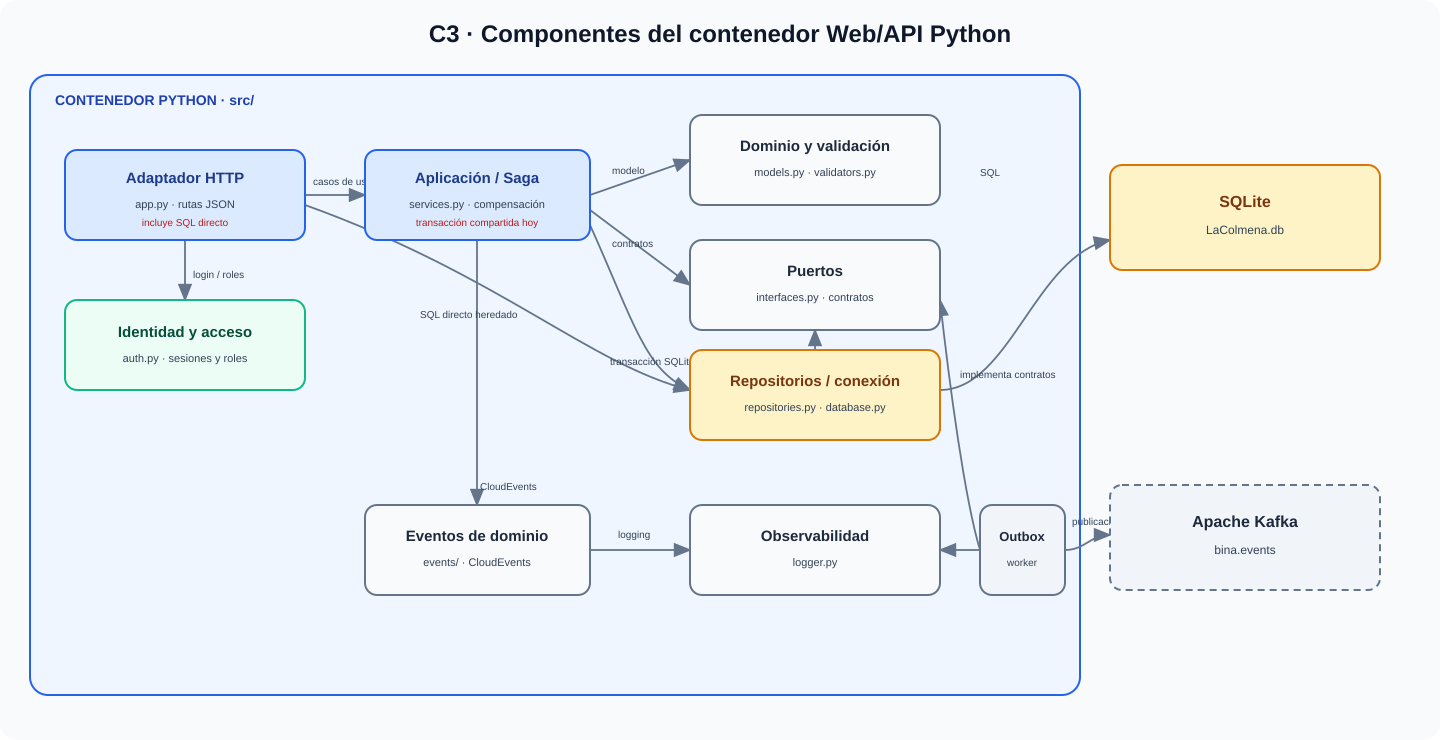

In [3]:
from IPython.display import SVG, display

display(SVG("""
<svg xmlns='http://www.w3.org/2000/svg' viewBox='0 0 1440 740' role='img' aria-label='Diagrama C3 de componentes del contenedor Python'>
  <defs><marker id='c3-arrow' markerWidth='10' markerHeight='8' refX='9' refY='4' orient='auto'><path d='M0,0 L10,4 L0,8 Z' fill='#64748b'/></marker></defs>
  <rect width='1440' height='740' rx='18' fill='#f8fafc'/>
  <text x='720' y='42' text-anchor='middle' font-family='Arial' font-size='24' font-weight='700' fill='#0f172a'>C3 · Componentes del contenedor Web/API Python</text>
  <rect x='30' y='75' width='1050' height='620' rx='18' fill='#eff6ff' stroke='#2563eb' stroke-width='2'/><text x='55' y='105' font-family='Arial' font-size='14' font-weight='700' fill='#1e40af'>CONTENEDOR PYTHON · src/</text>
  <g fill='none' stroke='#64748b' stroke-width='1.8' marker-end='url(#c3-arrow)'>
    <path d='M305 195 L365 195'/><path d='M185 240 L185 300'/><path d='M305 205 C500 275 590 365 690 390'/>
    <path d='M590 195 L690 160'/><path d='M590 210 L690 285'/><path d='M590 225 C635 325 645 370 690 390'/><path d='M477 240 L477 505'/>
    <path d='M940 390 C1010 390 1035 255 1110 240'/><path d='M940 390 L940 430 L815 430 L815 330'/><path d='M980 550 C965 500 950 390 940 300'/><path d='M1065 550 C1085 550 1090 535 1110 535'/><path d='M980 550 L940 550'/><path d='M590 550 L690 550'/>
  </g>
  <g font-family='Arial' font-size='10' fill='#334155'><text x='313' y='185'>casos de uso</text><text x='193' y='278'>login / roles</text><text x='420' y='318'>SQL directo heredado</text><text x='612' y='174'>modelo</text><text x='612' y='247'>contratos</text><text x='610' y='365'>transacción SQLite</text><text x='480' y='490'>CloudEvents</text><text x='980' y='176'>SQL</text><text x='960' y='378'>implementa contratos</text><text x='1072' y='525'>publicación</text><text x='618' y='538'>logging</text></g>
  <g font-family='Arial'>
    <rect x='65' y='150' width='240' height='90' rx='12' fill='#dbeafe' stroke='#2563eb' stroke-width='2'/><text x='185' y='183' text-anchor='middle' font-size='15' font-weight='700' fill='#1e3a8a'>Adaptador HTTP</text><text x='185' y='208' text-anchor='middle' font-size='11' fill='#334155'>app.py · rutas JSON</text><text x='185' y='226' text-anchor='middle' font-size='10' fill='#b91c1c'>incluye SQL directo</text>
    <rect x='65' y='300' width='240' height='90' rx='12' fill='#ecfdf5' stroke='#10b981' stroke-width='2'/><text x='185' y='337' text-anchor='middle' font-size='15' font-weight='700' fill='#064e3b'>Identidad y acceso</text><text x='185' y='362' text-anchor='middle' font-size='11' fill='#334155'>auth.py · sesiones y roles</text>
    <rect x='365' y='150' width='225' height='90' rx='12' fill='#dbeafe' stroke='#2563eb' stroke-width='2'/><text x='477' y='183' text-anchor='middle' font-size='15' font-weight='700' fill='#1e3a8a'>Aplicación / Saga</text><text x='477' y='208' text-anchor='middle' font-size='11' fill='#334155'>services.py · compensación</text><text x='477' y='226' text-anchor='middle' font-size='10' fill='#b91c1c'>transacción compartida hoy</text>
    <rect x='365' y='505' width='225' height='90' rx='12' fill='#f8fafc' stroke='#64748b' stroke-width='2'/><text x='477' y='541' text-anchor='middle' font-size='15' font-weight='700' fill='#1e293b'>Eventos de dominio</text><text x='477' y='566' text-anchor='middle' font-size='11' fill='#334155'>events/ · CloudEvents</text>
    <rect x='690' y='115' width='250' height='90' rx='12' fill='#f8fafc' stroke='#64748b' stroke-width='2'/><text x='815' y='151' text-anchor='middle' font-size='15' font-weight='700' fill='#1e293b'>Dominio y validación</text><text x='815' y='176' text-anchor='middle' font-size='11' fill='#334155'>models.py · validators.py</text>
    <rect x='690' y='240' width='250' height='90' rx='12' fill='#f8fafc' stroke='#64748b' stroke-width='2'/><text x='815' y='276' text-anchor='middle' font-size='15' font-weight='700' fill='#1e293b'>Puertos</text><text x='815' y='301' text-anchor='middle' font-size='11' fill='#334155'>interfaces.py · contratos</text>
    <rect x='690' y='350' width='250' height='90' rx='12' fill='#fef3c7' stroke='#d97706' stroke-width='2'/><text x='815' y='386' text-anchor='middle' font-size='15' font-weight='700' fill='#78350f'>Repositorios / conexión</text><text x='815' y='411' text-anchor='middle' font-size='11' fill='#334155'>repositories.py · database.py</text>
    <rect x='690' y='505' width='250' height='90' rx='12' fill='#f8fafc' stroke='#64748b' stroke-width='2'/><text x='815' y='541' text-anchor='middle' font-size='15' font-weight='700' fill='#1e293b'>Observabilidad</text><text x='815' y='566' text-anchor='middle' font-size='11' fill='#334155'>logger.py</text>
    <rect x='980' y='505' width='85' height='90' rx='12' fill='#f1f5f9' stroke='#64748b' stroke-width='2'/><text x='1022' y='541' text-anchor='middle' font-size='13' font-weight='700' fill='#1e293b'>Outbox</text><text x='1022' y='566' text-anchor='middle' font-size='10' fill='#334155'>worker</text>
    <rect x='1110' y='165' width='270' height='105' rx='12' fill='#fef3c7' stroke='#d97706' stroke-width='2'/><text x='1245' y='207' text-anchor='middle' font-size='16' font-weight='700' fill='#78350f'>SQLite</text><text x='1245' y='234' text-anchor='middle' font-size='12' fill='#334155'>LaColmena.db</text>
    <rect x='1110' y='485' width='270' height='105' rx='12' fill='#f1f5f9' stroke='#64748b' stroke-width='2' stroke-dasharray='7 5'/><text x='1245' y='527' text-anchor='middle' font-size='16' font-weight='700' fill='#1e293b'>Apache Kafka</text><text x='1245' y='554' text-anchor='middle' font-size='12' fill='#334155'>bina.events</text>
  </g>
</svg>
"""))


## Lectura del modelo y brechas

- **C1:** muestra usuarios y el broker externo, no detalles internos de despliegue.
- **C2:** el cliente web, el proceso Python, SQLite y Kafka son los contenedores principales.
- **C3:** las rutas HTTP todavía acceden directamente a varias tablas; `services.py` también administra una transacción SQLite que cruza pedido, catálogo y outbox.
- Para completar Bounded Contexts estrictos, cada contexto debe ser el único propietario de sus tablas; las llamadas entre contextos deben pasar por contratos y eventos, no por SQL compartido. Ver el [documento D2](../docs/D2_MODELADO_C4_ISO25010_BOUNDED_CONTEXTS.md) para el mapa de propiedad, métricas Ca/Ce/I/D y criterios ISO 25010.
